## Contexto do Problema

Dataset: Bank Marketing (Kaggle/UCI). O objetivo é prever se um cliente de um banco português vai aderir a um depósito a prazo (`y = yes/no`) com base em dados demográficos e de campanhas telefônicas anteriores.

**Dicionário de dados (principais colunas):**
| Coluna | Tipo | Significado |
|--------|------|-------------|
| age | int | Idade do cliente |
| job | categórico | Profissão |
| marital | categórico | Estado civil |
| education | categórico | Escolaridade |
| balance | int | Saldo médio anual (euros) |
| duration | int | Duração da última ligação (segundos) |
| campaign | int | Nº de contatos nesta campanha |
| pdays | int | Dias desde o último contato (-1 = nunca) |
| previous | int | Nº de contatos anteriores |
| poutcome | categórico | Resultado da campanha anterior |
| y | binário | **Target**: assinou o depósito? |

In [2]:
print(df.shape)

(210, 7)


Shape: (11162, 17)

Valores ausentes:
 age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
deposit      0
dtype: int64

Distribuição do target:
 deposit
no     5873
yes    5289
Name: count, dtype: int64


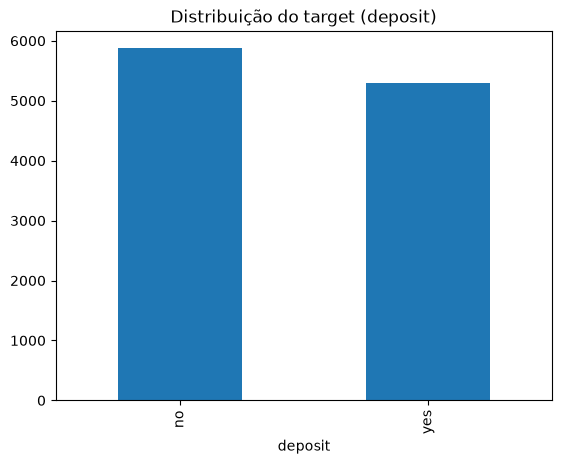

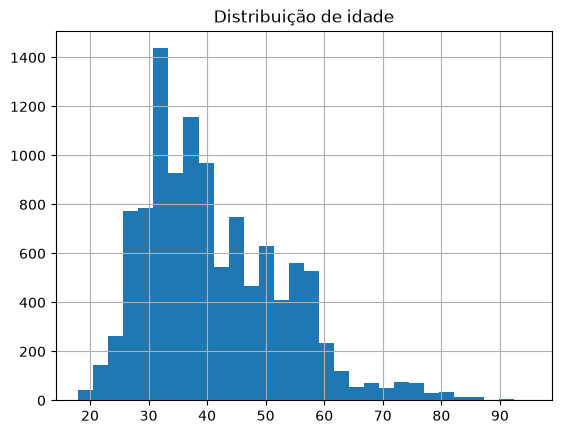

In [3]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv("../data/dataset.csv")
print("Shape:", df.shape)
print("\nValores ausentes:\n", df.isnull().sum())

# Target correta: deposit
print("\nDistribuição do target:\n", df["deposit"].value_counts())
df["deposit"].value_counts().plot(kind="bar", title="Distribuição do target (deposit)")
plt.show()

df["age"].hist(bins=30)
plt.title("Distribuição de idade")
plt.show()

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X = df.drop(columns=["deposit"])
y = df["deposit"]

num_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X.select_dtypes(include=["object"]).columns.tolist()

print("Numéricas:", num_cols)
print("Categóricas:", cat_cols)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", MLPClassifier(
        hidden_layer_sizes=(128, 64, 32),   # 3 camadas ocultas (≥2 exigido)
        learning_rate_init=0.001,
        max_iter=500,
        random_state=77,
        early_stopping=True,                # ajuda na convergência
        n_iter_no_change=15
    ))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=77, stratify=y
)

pipeline.fit(X_train, y_train)
print("Treinamento concluído.")

C:\Users\Erlon\AppData\Local\Temp\ipykernel_18272\743977318.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object"]).columns.tolist()


Numéricas: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
Categóricas: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Treinamento concluído.


Matthews Correlation Coefficient (MCC): 0.7096


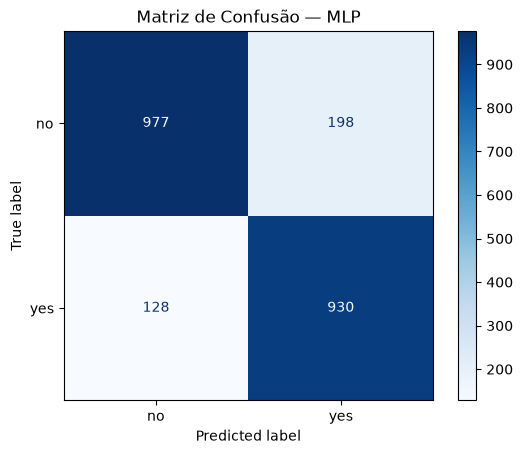

In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, matthews_corrcoef

y_pred = pipeline.predict(X_test)

mcc = matthews_corrcoef(y_test, y_pred)
print(f"Matthews Correlation Coefficient (MCC): {mcc:.4f}")

cm = confusion_matrix(y_test, y_pred, labels=pipeline.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=pipeline.classes_)
disp.plot(cmap="Blues")
plt.title("Matriz de Confusão — MLP")
plt.show()

In [6]:
import os

import joblib

os.makedirs("../models", exist_ok=True)
joblib.dump(pipeline, "../models/pipeline_rede_neural.joblib")
print("Pipeline salvo em models/pipeline_rede_neural.joblib")

Pipeline salvo em models/pipeline_rede_neural.joblib
